In [2]:
import numpy as np 
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.svm import SVR
import time
import seaborn as sns
from joblib import Parallel, delayed
from pathlib import Path

plt.rcParams['font.size'] = 14

# The amount of variance we want the PCA to explain
explained_variance = 0.99

We start by importing the data, splitting out the risk factor as 'y' and normalizing the data 'x'. 

In [3]:
Input = pd.read_csv("data/Project_Data_EE4C12_EPE_PS.csv", delimiter=',')

y = Input['Risk Factor']
x = Input.drop(columns='Risk Factor')

x_scaled = StandardScaler().fit_transform(x)

We can become more familiar with our data, by plotting it in various ways.

In [4]:
print(list(x))
print(x.shape)
print("217 Features, 4955 observations")

['Unnamed: 0', 'Bus Voltage-1', 'Bus Voltage-2', 'Bus Voltage-3', 'Bus Voltage-4', 'Bus Voltage-5', 'Bus Voltage-6', 'Bus Voltage-7', 'Bus Voltage-8', 'Bus Voltage-9', 'Bus Angles-1', 'Bus Angles-2', 'Bus Angles-3', 'Bus Angles-4', 'Bus Angles-5', 'Bus Angles-6', 'Bus Angles-7', 'Bus Angles-8', 'Bus Angles-9', ' P generation-1', ' P generation-2', ' P generation-3', ' P generation-4', ' P generation-5', ' P generation-6', ' P generation-7', ' P generation-8', ' P generation-9', 'Q generation-1', 'Q generation-2', 'Q generation-3', 'Q generation-4', 'Q generation-5', 'Q generation-6', 'Q generation-7', 'Q generation-8', 'Q generation-9', 'P demand-1', 'P demand-2', 'P demand-3', 'P demand-4', 'P demand-5', 'P demand-6', 'P demand-7', 'P demand-8', 'P demand-9', 'Q demand-1', 'Q demand-2', 'Q demand-3', 'Q demand-4', 'Q demand-5', 'Q demand-6', 'Q demand-7', 'Q demand-8', 'Q demand-9', 'Pflow Bus 1-1', 'Pflow Bus 1-2', 'Pflow Bus 1-3', 'Pflow Bus 1-4', 'Pflow Bus 1-5', 'Pflow Bus 1-6', '

[]

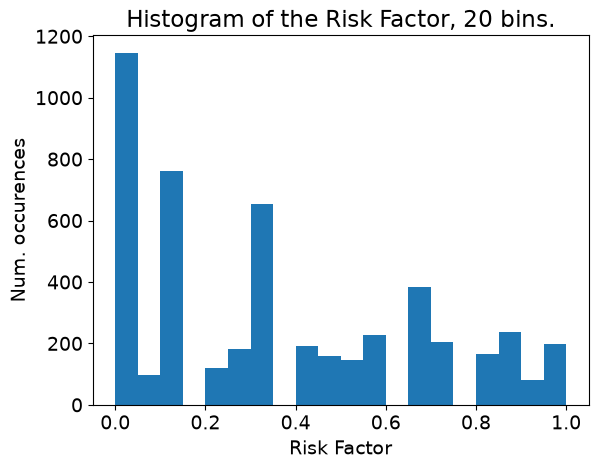

In [5]:
plt.figure()
plt.hist(y, bins=20)
plt.title("Histogram of the Risk Factor, 20 bins.")
plt.xlabel("Risk Factor")
plt.ylabel("Num. occurences")
plt.plot()

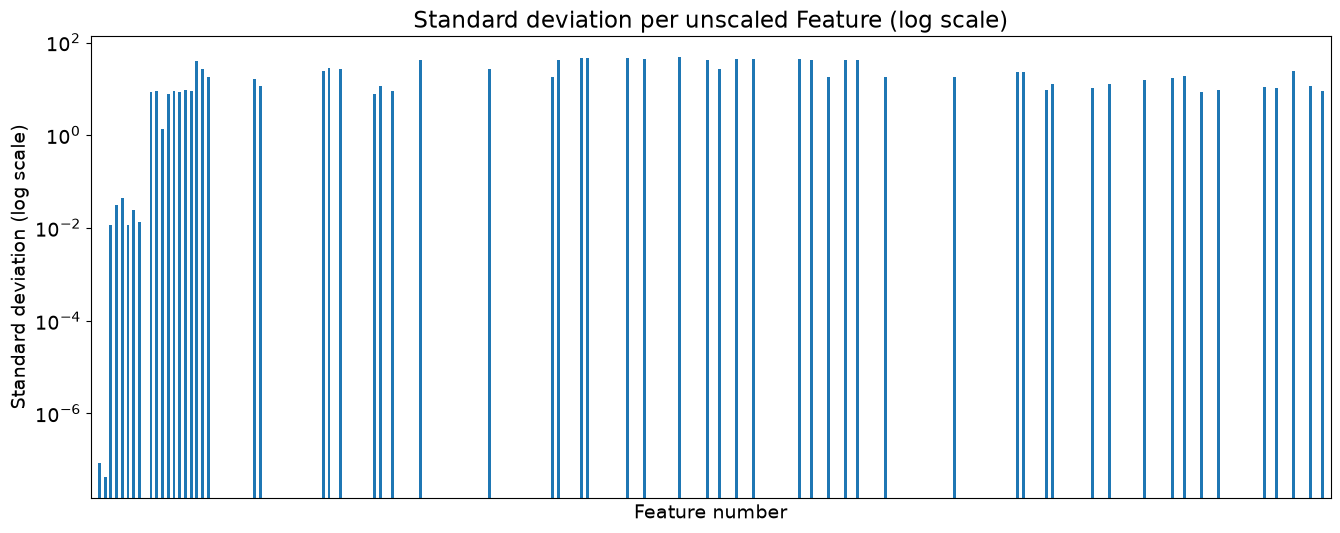

In [6]:
plt.figure(figsize=(16,6))
plt.title("Standard deviation per unscaled Feature (log scale)")
plt.xlabel("Feature number")
stds = x.iloc[:, 1:].select_dtypes(include="number").std()
stds.plot(kind="bar")
plt.xticks([], [])
plt.yscale('log')
plt.ylabel("Standard deviation (log scale)")
plt.show()

We can see that there are a lot of features which have no variance at all. These are not interesting to use as training data, as they do not contribute any knowlege to the problem. We can remove them 

In [7]:
stds = x.select_dtypes(include="number").std()

zero_deviation_columns = stds[stds == 0].index.tolist()
x_cleaned = x.drop(columns=zero_deviation_columns)

print(f"Dropped {len(zero_deviation_columns)} constant columns")
print("New shape of x:")
print(x_cleaned.shape)

Dropped 153 constant columns
New shape of x:
(4955, 64)


To get an idea of what how this data relates internally, we can make a correlation matrix. 

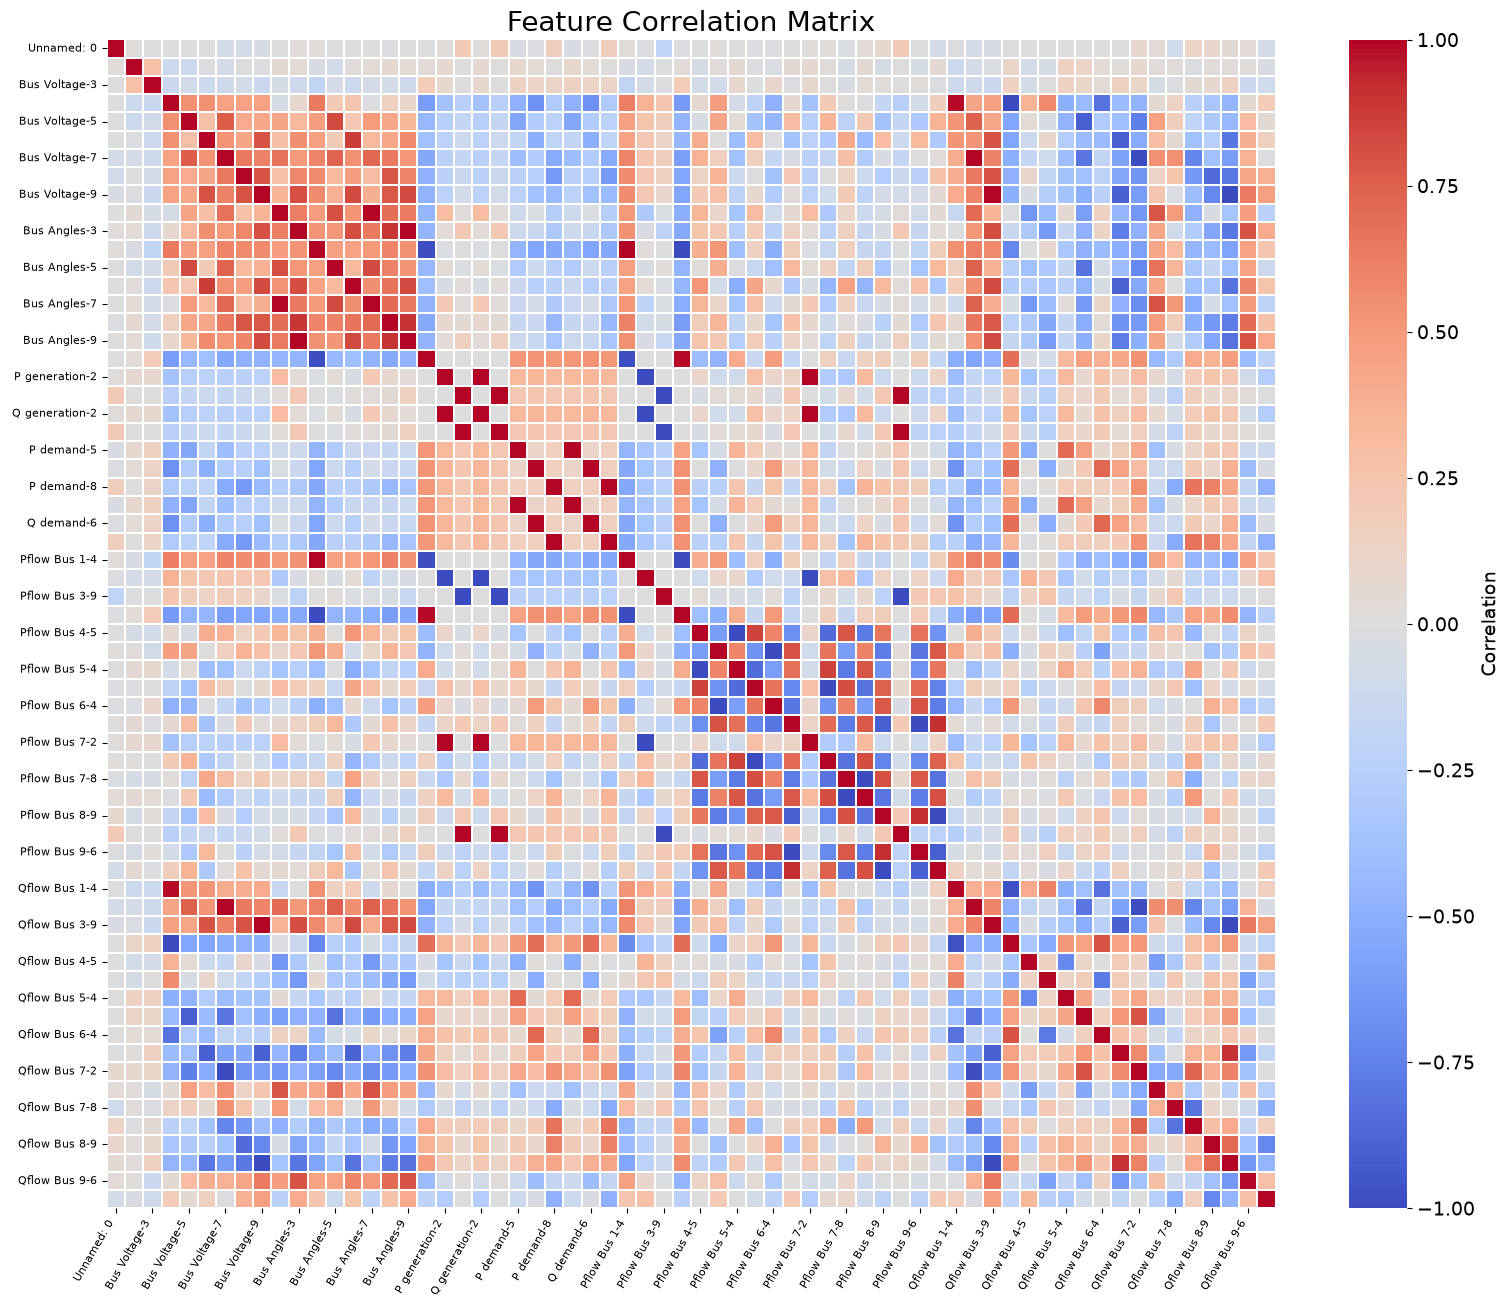

In [8]:
def plot_correlation_matrix(df):
    # Compute full correlation matrix
    corr = df.corr()

    # Scale figure size based on number of features
    n_features = len(corr.columns)
    fig_size = max(14, n_features * 0.25)

    plt.figure(figsize=(fig_size, fig_size))

    sns.heatmap(
        corr,
        cmap="coolwarm", center=0, vmin=-1, vmax=1,

        # Important for a large matrix:
        annot=False,          # Don't print a number in every cell
        square=True,
        linewidths=0.15,

        cbar_kws={
            "label": "Correlation",
            "shrink": 0.75
        }
    )

    plt.title("Feature Correlation Matrix", fontsize=20,)
    plt.xticks(rotation=60,ha="right",fontsize=8)
    plt.yticks(fontsize=8)
    plt.tight_layout()
    plt.show()

plot_correlation_matrix(x_cleaned)


# PCA

We can see from the correlation that many of the variables are weakly correlated with one another. Only a few variables are strongly correlated. With a principal component analysis (PCA), we might be able to further reduce the amount of variables our model would have to accomodate for, thus reducing the training time required.

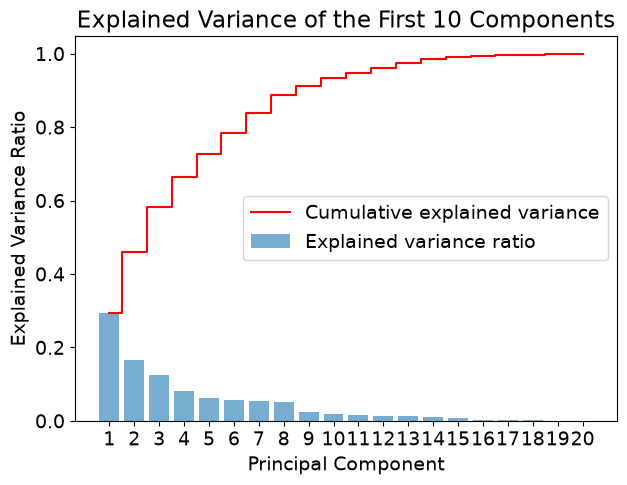

In [9]:
pca = PCA(n_components=20)
pca_fitted = pca.fit_transform(x_scaled)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
components = np.arange(1, 21)

plt.figure(figsize=(7, 5))
plt.bar(components, explained, alpha=0.6, label='Explained variance ratio')
plt.step(components, cumulative, where='mid', color='red', label='Cumulative explained variance')
plt.xticks(components)
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Explained Variance of the First 10 Components')
plt.legend()
plt.show()

#for i in range(20):
#    print(f'Variance explained by component {i+1}: {cumulative[i]*100:.2f}%')


We can see the variance in the dataset is not dominated by any principal components. We can see that the amount of components we need to explain certain variance levels is:

80%: 7 components

90%: 9 components

95%: 12 components

99%: 15 components


In [10]:
# Add components until we explained 99% of variance.
pca = PCA(n_components = explained_variance) 
x_reduced = pca.fit_transform(x_scaled)
print(f"Shape of x_reduced: {x_reduced.shape}")
print(f"Explained variance: {pca.explained_variance_ratio_.sum()}")

Shape of x_reduced: (4955, 15)
Explained variance: 0.991814092011734


We can now write the preprocessed data into a CSV file, so that we can manipulate it in another Jupyter Notebook. For clarity.

In [11]:
x_reduced_df = pd.DataFrame(x_reduced, columns=[f'PC{i+1}' for i in range(x_reduced.shape[1])], index=x.index)

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

x_reduced_df.to_csv(data_dir / "processed_data.csv", index=True)
y.to_csv(data_dir / "processed_target.csv", index=True, header=True)

In this graphic the first two components of the PCA are presented on the x and y - axis and the color of the dot represents the operational risk of this sample

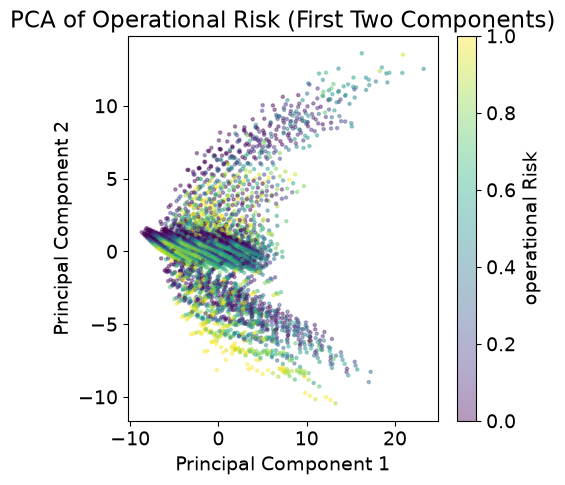

In [13]:
# Plot the first two principal components of each point
plt.figure(figsize=(5,5))
plt.scatter(x_reduced[:, 0], x_reduced[:, 1], c=y, cmap='viridis', alpha=0.4, s=5)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Operational Risk (First Two Components)')
plt.colorbar(label='operational Risk')
plt.show()